NOTEBOOK 10 — COST-SENSITIVE LEARNING

Configuration:
Random State: 42
Test Size: 0.2
Cross-Validation Folds: 5
Output Directory: cost_sensitive_model_results

DATASET LOADED
Dataset Shape: (10000, 45)

DATA VALIDATION

Missing Values: 0
Duplicate Rows: 0

Target Distribution:
churn
0    8979
1    1021
Name: count, dtype: int64

Target Distribution (%):
churn
0    89.79
1    10.21
Name: proportion, dtype: float64

FEATURES AND TARGET
Feature Shape: (10000, 44)
Target Shape: (10000,)

TRAIN / TEST SPLIT

Training Shape: (8000, 44)
Testing Shape: (2000, 44)

Training Target Distribution:
churn
0    7183
1     817
Name: count, dtype: int64

Testing Target Distribution:
churn
0    1796
1     204
Name: count, dtype: int64

FEATURE TYPES

Categorical Variables: 11
['gender', 'country', 'city', 'customer_segment', 'signup_channel', 'contract_type', 'payment_method', 'discount_applied', 'price_increase_last_3m', 'complaint_type', 'survey_response']

Numerical Variables: 33
['age', 'tenure_mont

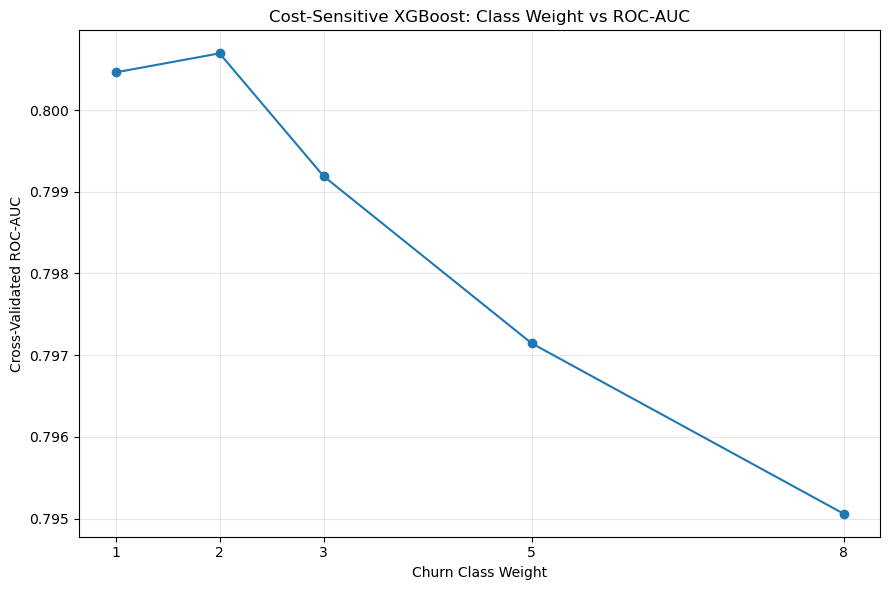

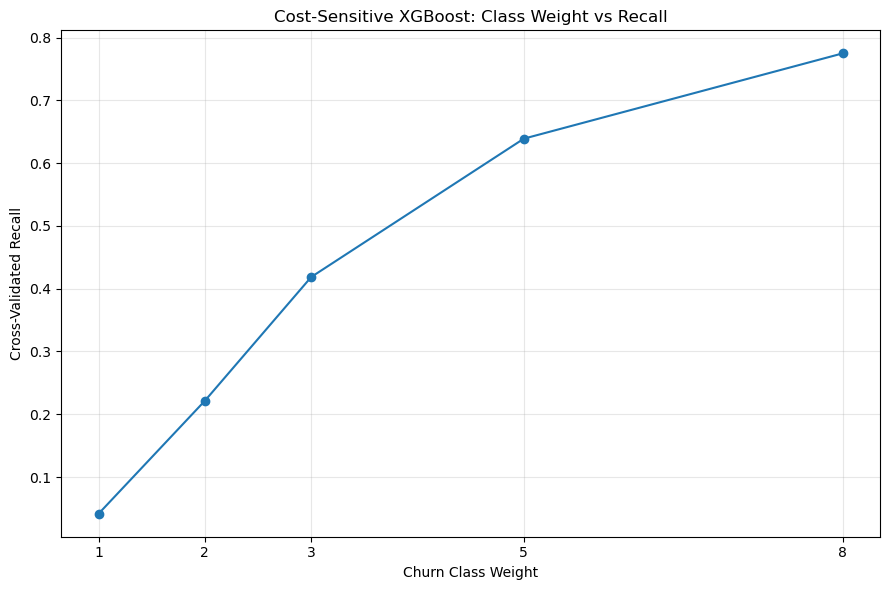

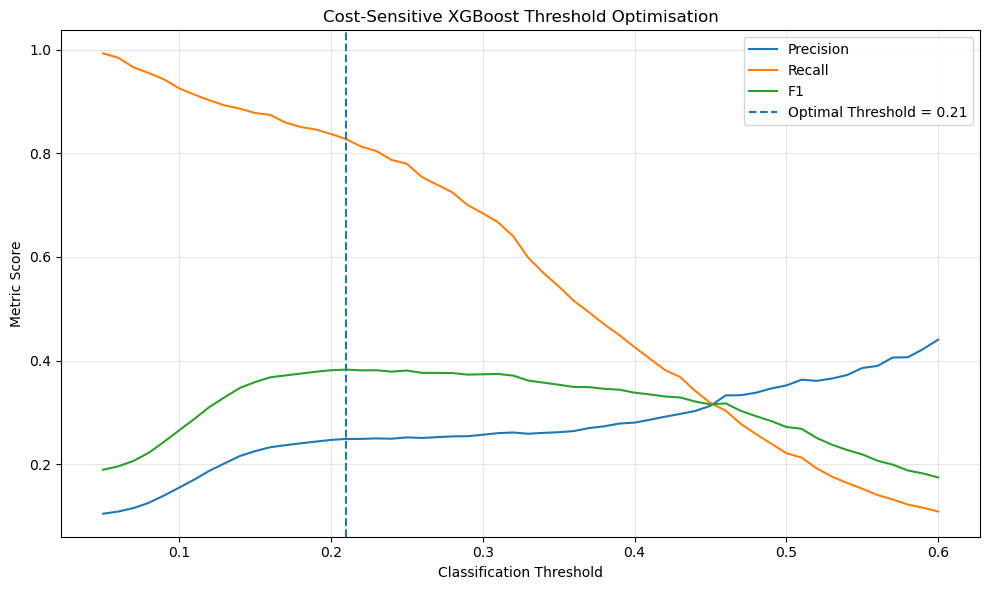

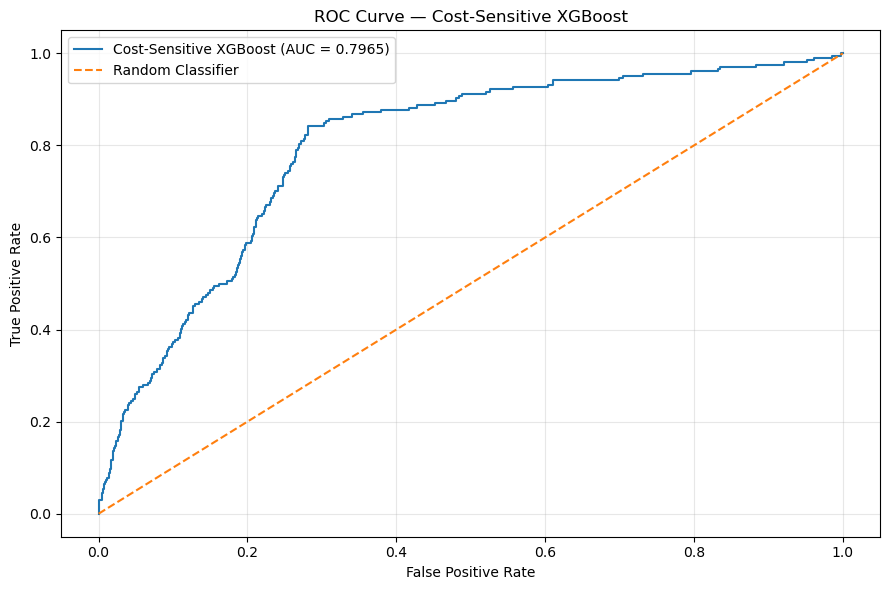

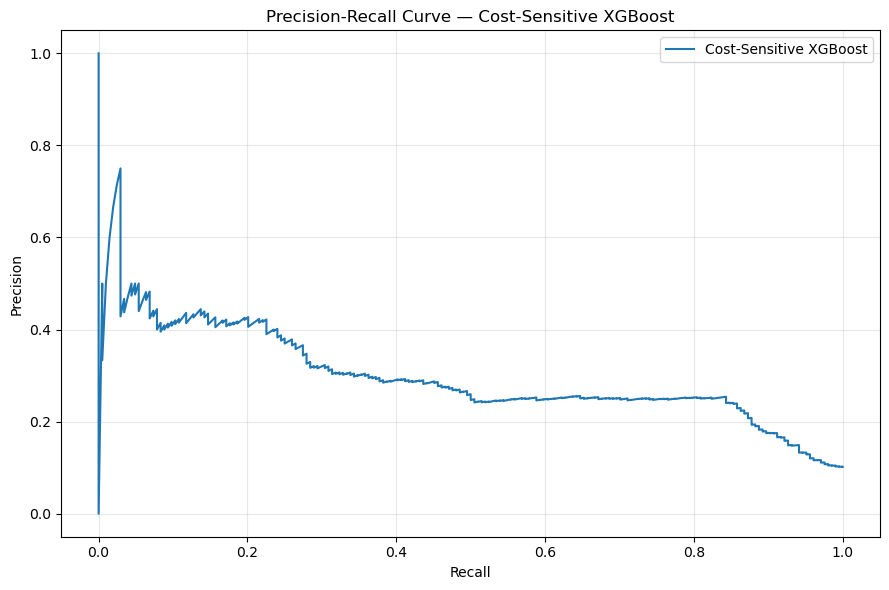

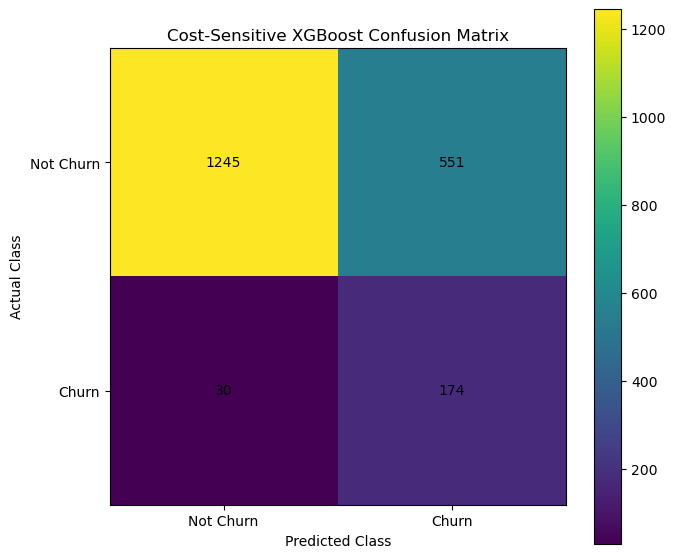


SAVING RESULTS

NOTEBOOK 10 — COST-SENSITIVE LEARNING COMPLETED

Selected Model:
Cost-Sensitive XGBoost

Selected Churn Class Weight: 2:1
Optimal Classification Threshold: 0.21

Final Test Results:
                    Model  Threshold  Accuracy  Precision  Recall      F1  \
0  Cost-Sensitive XGBoost       0.50    0.8810     0.3786  0.2598  0.3081   
1  Cost-Sensitive XGBoost       0.21    0.7095     0.2400  0.8529  0.3746   

   ROC_AUC  Average_Precision  Balanced_Accuracy  Specificity  Business_Cost  
0   0.7965             0.3004             0.6057       0.9516            842  
1   0.7965             0.3004             0.7731       0.6932            701  

Confusion Matrix:
[[1245  551]
 [  30  174]]

Output Directory:
cost_sensitive_model_results

Saved Files:
 - Best_Cost_Sensitive_XGBoost.pkl
 - Business_Cost_Scenarios.csv
 - Class_Weight_vs_ROC_AUC.png
 - Class_Weight_vs_Recall.png
 - Cost_Sensitive_CV_Results.csv
 - Cost_Sensitive_Confusion_Matrix.png
 - Cost_Sensitive_Final_T

In [ ]:
# ======================================================================
# NOTEBOOK 10 — COST-SENSITIVE LEARNING
# ======================================================================
#
# Dissertation:
# "Hybrid Interpretable Machine Learning Model for Customer Churn
#  Prediction with Real-World Validation"
#
# Objective:
# Develop and evaluate cost-sensitive churn prediction models by
# assigning greater importance to the minority churn class and
# explicitly analysing the business trade-off between:
#
#       False Negatives = Missed Churners
#       False Positives = Unnecessary Retention Actions
#
# Methodology:
#   1. Load feature-engineered dataset
#   2. Validate dataset
#   3. Stratified train/test split
#   4. Leakage-safe preprocessing
#   5. Develop cost-sensitive Logistic Regression
#   6. Develop cost-sensitive XGBoost
#   7. Evaluate class-weight configurations
#   8. Perform cross-validation
#   9. Optimise classification threshold using training CV
#  10. Evaluate final models on unseen test data
#  11. Calculate business cost under multiple cost scenarios
#  12. Compare standard vs cost-sensitive models
#  13. Save models, metrics, predictions and visualisations
#
# ======================================================================


# ======================================================================
# 1. LIBRARIES
# ======================================================================

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)

from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier

warnings.filterwarnings("ignore")


# ======================================================================
# 2. CONFIGURATION
# ======================================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5

OUTPUT_DIR = "cost_sensitive_model_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 70)
print("NOTEBOOK 10 — COST-SENSITIVE LEARNING")
print("=" * 70)

print("\nConfiguration:")
print(f"Random State: {RANDOM_STATE}")
print(f"Test Size: {TEST_SIZE}")
print(f"Cross-Validation Folds: {CV_FOLDS}")
print(f"Output Directory: {OUTPUT_DIR}")


# ======================================================================
# 3. LOAD DATASET
# ======================================================================

DATA_PATH = "customer_churn_feature_engineered.csv"

df = pd.read_csv(DATA_PATH)

print("\n" + "=" * 70)
print("DATASET LOADED")
print("=" * 70)

print(f"Dataset Shape: {df.shape}")


# ======================================================================
# 4. DATA VALIDATION
# ======================================================================

print("\n" + "=" * 70)
print("DATA VALIDATION")
print("=" * 70)

missing_values = df.isnull().sum().sum()
duplicate_rows = df.duplicated().sum()

print(f"\nMissing Values: {missing_values}")
print(f"Duplicate Rows: {duplicate_rows}")

print("\nTarget Distribution:")
print(df["churn"].value_counts())

print("\nTarget Distribution (%):")
print(
    df["churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


# ======================================================================
# 5. FEATURES AND TARGET
# ======================================================================

X = df.drop(columns=["churn"])
y = df["churn"]

print("\n" + "=" * 70)
print("FEATURES AND TARGET")
print("=" * 70)

print(f"Feature Shape: {X.shape}")
print(f"Target Shape: {y.shape}")


# ======================================================================
# 6. TRAIN / TEST SPLIT
# ======================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

print("\n" + "=" * 70)
print("TRAIN / TEST SPLIT")
print("=" * 70)

print(f"\nTraining Shape: {X_train.shape}")
print(f"Testing Shape: {X_test.shape}")

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())


# ======================================================================
# 7. FEATURE TYPES
# ======================================================================

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("\n" + "=" * 70)
print("FEATURE TYPES")
print("=" * 70)

print(f"\nCategorical Variables: {len(categorical_features)}")
print(categorical_features)

print(f"\nNumerical Variables: {len(numerical_features)}")
print(numerical_features)


# ======================================================================
# 8. LEAKAGE-SAFE PREPROCESSING
# ======================================================================

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("\n" + "=" * 70)
print("PREPROCESSING")
print("=" * 70)

print("\nLeakage-safe preprocessing pipeline created.")
print("Numerical variables: median imputation + StandardScaler")
print("Categorical variables: mode imputation + OneHotEncoder")
print("Preprocessing is fitted only inside training folds.")


# ======================================================================
# 9. CROSS-VALIDATION CONFIGURATION
# ======================================================================

cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("\n" + "=" * 70)
print("CROSS-VALIDATION")
print("=" * 70)

print("Method: Stratified 5-Fold Cross-Validation")
print(f"Random State: {RANDOM_STATE}")


# ======================================================================
# 10. BASELINE COST STRUCTURE
# ======================================================================
#
# Business interpretation:
#
# False Negative:
# Customer actually churns but model predicts "Not Churn".
#
# False Positive:
# Customer does not churn but model predicts "Churn".
#
# We assume that missing a churner is more costly than incorrectly
# targeting a retained customer.
#
# These values are scenario assumptions for methodological analysis.
# They are NOT claimed to represent an actual company's financial costs.
#
# ======================================================================

FN_COST = 5
FP_COST = 1

print("\n" + "=" * 70)
print("BUSINESS COST ASSUMPTIONS")
print("=" * 70)

print("\nBase Cost Scenario:")
print(f"False Negative Cost: {FN_COST}")
print(f"False Positive Cost: {FP_COST}")

print(
    "\nInterpretation:"
    "\nMissing a churner is assumed to be 5 times more costly "
    "than incorrectly targeting a non-churner."
)


# ======================================================================
# 11. COST FUNCTION
# ======================================================================

def calculate_business_cost(
    y_true,
    y_pred,
    fn_cost=5,
    fp_cost=1
):
    """
    Calculate total business cost.

    Cost =
        False Negatives × FN Cost
        +
        False Positives × FP Cost
    """

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    total_cost = (
        (fn * fn_cost)
        +
        (fp * fp_cost)
    )

    return {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Total_Cost": total_cost
    }


# ======================================================================
# 12. MODEL CONFIGURATIONS
# ======================================================================
#
# Logistic Regression:
# class_weight controls the relative importance of the churn class.
#
# XGBoost:
# scale_pos_weight increases the importance of positive churn examples.
#
# The training class ratio is:
#
#       Non-Churn / Churn
#
# ======================================================================

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

base_scale_pos_weight = negative_count / positive_count

print("\n" + "=" * 70)
print("CLASS IMBALANCE RATIO")
print("=" * 70)

print(f"\nTraining Non-Churn: {negative_count}")
print(f"Training Churn: {positive_count}")

print(
    f"\nNatural XGBoost scale_pos_weight: "
    f"{base_scale_pos_weight:.4f}"
)


# ======================================================================
# 13. COST-SENSITIVE WEIGHT CONFIGURATIONS
# ======================================================================
#
# Logistic Regression:
#
# 1:1 = equal class importance
# 2:1 = churn twice as important
# 3:1 = churn three times as important
# 5:1 = churn five times as important
# 8:1 = churn eight times as important
#
# XGBoost uses the same conceptual ratios through scale_pos_weight.
#
# ======================================================================

weight_configs = [1, 2, 3, 5, 8]

print("\n" + "=" * 70)
print("COST-SENSITIVE WEIGHT CONFIGURATIONS")
print("=" * 70)

print("\nCandidate churn class weights:")
print(weight_configs)


# ======================================================================
# 14. CREATE MODEL PIPELINES
# ======================================================================

def create_logistic_pipeline(class_weight_ratio):

    return ImbPipeline(
        steps=[
            (
                "preprocessing",
                preprocessor
            ),

            (
                "smote",
                SMOTE(
                    random_state=RANDOM_STATE
                )
            ),

            (
                "model",
                LogisticRegression(
                    C=0.001,
                    solver="liblinear",
                    class_weight={
                        0: 1,
                        1: class_weight_ratio
                    },
                    max_iter=2000,
                    random_state=RANDOM_STATE
                )
            )
        ]
    )


def create_xgb_pipeline(scale_pos_weight):

    return ImbPipeline(
        steps=[
            (
                "preprocessing",
                preprocessor
            ),

            (
                "smote",
                SMOTE(
                    random_state=RANDOM_STATE
                )
            ),

            (
                "model",
                XGBClassifier(
                    n_estimators=200,
                    max_depth=3,
                    learning_rate=0.05,
                    min_child_weight=1,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    scale_pos_weight=scale_pos_weight,
                    eval_metric="logloss",
                    random_state=RANDOM_STATE,
                    n_jobs=-1
                )
            )
        ]
    )


# ======================================================================
# 15. CROSS-VALIDATED COST-SENSITIVE MODEL EVALUATION
# ======================================================================

print("\n" + "=" * 70)
print("COST-SENSITIVE CROSS-VALIDATION")
print("=" * 70)

cost_sensitive_results = []

for weight in weight_configs:

    print(
        f"\nEvaluating class-weight configuration: "
        f"{weight}:1"
    )

    # --------------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------------

    lr_pipeline = create_logistic_pipeline(weight)

    lr_oof_prob = cross_val_predict(
        lr_pipeline,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    lr_oof_pred = (
        lr_oof_prob >= 0.50
    ).astype(int)

    lr_auc = roc_auc_score(
        y_train,
        lr_oof_prob
    )

    lr_ap = average_precision_score(
        y_train,
        lr_oof_prob
    )

    lr_precision = precision_score(
        y_train,
        lr_oof_pred,
        zero_division=0
    )

    lr_recall = recall_score(
        y_train,
        lr_oof_pred,
        zero_division=0
    )

    lr_f1 = f1_score(
        y_train,
        lr_oof_pred,
        zero_division=0
    )

    lr_bal_acc = balanced_accuracy_score(
        y_train,
        lr_oof_pred
    )

    # --------------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------------

    xgb_pipeline = create_xgb_pipeline(
        weight
    )

    xgb_oof_prob = cross_val_predict(
        xgb_pipeline,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    xgb_oof_pred = (
        xgb_oof_prob >= 0.50
    ).astype(int)

    xgb_auc = roc_auc_score(
        y_train,
        xgb_oof_prob
    )

    xgb_ap = average_precision_score(
        y_train,
        xgb_oof_prob
    )

    xgb_precision = precision_score(
        y_train,
        xgb_oof_pred,
        zero_division=0
    )

    xgb_recall = recall_score(
        y_train,
        xgb_oof_pred,
        zero_division=0
    )

    xgb_f1 = f1_score(
        y_train,
        xgb_oof_pred,
        zero_division=0
    )

    xgb_bal_acc = balanced_accuracy_score(
        y_train,
        xgb_oof_pred
    )

    xgb_cost = calculate_business_cost(
        y_train,
        xgb_oof_pred,
        FN_COST,
        FP_COST
    )

    cost_sensitive_results.append(
        {
            "Weight": weight,
            "Logistic_ROC_AUC": lr_auc,
            "Logistic_Average_Precision": lr_ap,
            "Logistic_Precision": lr_precision,
            "Logistic_Recall": lr_recall,
            "Logistic_F1": lr_f1,
            "Logistic_Balanced_Accuracy": lr_bal_acc,
            "XGBoost_ROC_AUC": xgb_auc,
            "XGBoost_Average_Precision": xgb_ap,
            "XGBoost_Precision": xgb_precision,
            "XGBoost_Recall": xgb_recall,
            "XGBoost_F1": xgb_f1,
            "XGBoost_Balanced_Accuracy": xgb_bal_acc,
            "XGBoost_TN": xgb_cost["TN"],
            "XGBoost_FP": xgb_cost["FP"],
            "XGBoost_FN": xgb_cost["FN"],
            "XGBoost_TP": xgb_cost["TP"],
            "XGBoost_Business_Cost": xgb_cost["Total_Cost"]
        }
    )


cost_results_df = pd.DataFrame(
    cost_sensitive_results
)

print("\n" + "=" * 70)
print("COST-SENSITIVE CROSS-VALIDATION RESULTS")
print("=" * 70)

print(
    cost_results_df[
        [
            "Weight",
            "Logistic_ROC_AUC",
            "Logistic_F1",
            "Logistic_Recall",
            "XGBoost_ROC_AUC",
            "XGBoost_F1",
            "XGBoost_Recall",
            "XGBoost_Business_Cost"
        ]
    ].round(4)
)


# ======================================================================
# 16. SELECT BEST COST-SENSITIVE XGBOOST CONFIGURATION
# ======================================================================
#
# Primary criterion:
# ROC-AUC
#
# Secondary consideration:
# Business cost and recall.
#
# ======================================================================

best_weight_row = cost_results_df.loc[
    cost_results_df["XGBoost_ROC_AUC"].idxmax()
]

best_weight = int(
    best_weight_row["Weight"]
)

best_cv_auc = best_weight_row[
    "XGBoost_ROC_AUC"
]

print("\n" + "=" * 70)
print("BEST COST-SENSITIVE CONFIGURATION")
print("=" * 70)

print(
    f"\nSelected XGBoost Churn Weight: "
    f"{best_weight}:1"
)

print(
    f"CV ROC-AUC: "
    f"{best_cv_auc:.4f}"
)

print(
    f"CV F1: "
    f"{best_weight_row['XGBoost_F1']:.4f}"
)

print(
    f"CV Recall: "
    f"{best_weight_row['XGBoost_Recall']:.4f}"
)

print(
    f"CV Business Cost: "
    f"{best_weight_row['XGBoost_Business_Cost']:.0f}"
)


# ======================================================================
# 17. THRESHOLD OPTIMISATION
# ======================================================================
#
# The classification threshold is optimised using training data only.
#
# Primary objective:
# Maximum F1.
#
# This avoids selecting the threshold using the final test set.
#
# ======================================================================

print("\n" + "=" * 70)
print("THRESHOLD OPTIMISATION")
print("=" * 70)

best_xgb_pipeline = create_xgb_pipeline(
    best_weight
)

threshold_oof_prob = cross_val_predict(
    best_xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]


threshold_values = np.arange(
    0.05,
    0.61,
    0.01
)

threshold_results = []

for threshold in threshold_values:

    threshold_pred = (
        threshold_oof_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_train,
        threshold_pred,
        zero_division=0
    )

    recall = recall_score(
        y_train,
        threshold_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_train,
        threshold_pred,
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_train,
        threshold_pred
    )

    cost = calculate_business_cost(
        y_train,
        threshold_pred,
        FN_COST,
        FP_COST
    )

    threshold_results.append(
        {
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "Balanced_Accuracy": balanced_acc,
            "TN": cost["TN"],
            "FP": cost["FP"],
            "FN": cost["FN"],
            "TP": cost["TP"],
            "Business_Cost": cost["Total_Cost"]
        }
    )


threshold_df = pd.DataFrame(
    threshold_results
)

best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

optimal_threshold = float(
    best_threshold_row["Threshold"]
)

print(
    f"\nOptimal Threshold: "
    f"{optimal_threshold:.2f}"
)

print("\nCross-Validated Performance:")

print(
    best_threshold_row[
        [
            "Threshold",
            "Precision",
            "Recall",
            "F1",
            "Balanced_Accuracy",
            "Business_Cost"
        ]
    ].round(4)
)


# ======================================================================
# 18. FINAL MODEL TRAINING
# ======================================================================

print("\n" + "=" * 70)
print("TRAINING FINAL COST-SENSITIVE MODEL")
print("=" * 70)

final_cost_sensitive_xgb = create_xgb_pipeline(
    best_weight
)

final_cost_sensitive_xgb.fit(
    X_train,
    y_train
)

print(
    "\nFinal cost-sensitive XGBoost model "
    "trained successfully."
)


# ======================================================================
# 19. FINAL TEST PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("FINAL TEST PREDICTIONS")
print("=" * 70)

test_probabilities = (
    final_cost_sensitive_xgb
    .predict_proba(X_test)[:, 1]
)

test_predictions_default = (
    test_probabilities >= 0.50
).astype(int)

test_predictions_optimal = (
    test_probabilities >= optimal_threshold
).astype(int)

print(
    "\nTest probabilities generated successfully."
)


# ======================================================================
# 20. EVALUATION FUNCTION
# ======================================================================

def evaluate_model(
    model_name,
    y_true,
    probabilities,
    predictions,
    threshold,
    fn_cost=5,
    fp_cost=1
):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    business_cost = (
        fn * fn_cost
        +
        fp * fp_cost
    )

    return {
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_true,
            predictions
        ),
        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_true,
            probabilities
        ),
        "Average_Precision": average_precision_score(
            y_true,
            probabilities
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_true,
            predictions
        ),
        "Specificity": specificity,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Business_Cost": business_cost
    }


# ======================================================================
# 21. FINAL TEST EVALUATION
# ======================================================================

default_results = evaluate_model(
    "Cost-Sensitive XGBoost",
    y_test,
    test_probabilities,
    test_predictions_default,
    0.50,
    FN_COST,
    FP_COST
)

optimal_results = evaluate_model(
    "Cost-Sensitive XGBoost",
    y_test,
    test_probabilities,
    test_predictions_optimal,
    optimal_threshold,
    FN_COST,
    FP_COST
)

final_test_results_df = pd.DataFrame(
    [
        default_results,
        optimal_results
    ]
)

print("\n" + "=" * 70)
print("FINAL TEST SET RESULTS")
print("=" * 70)

print(
    final_test_results_df[
        [
            "Model",
            "Threshold",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "Average_Precision",
            "Balanced_Accuracy",
            "Specificity",
            "Business_Cost"
        ]
    ].round(4)
)


# ======================================================================
# 22. CONFUSION MATRIX — OPTIMAL THRESHOLD
# ======================================================================

optimal_cm = confusion_matrix(
    y_test,
    test_predictions_optimal
)

print("\n" + "=" * 70)
print("COST-SENSITIVE CONFUSION MATRIX")
print("=" * 70)

print(optimal_cm)

tn, fp, fn, tp = optimal_cm.ravel()

print("\nConfusion Matrix Breakdown:")
print(f"True Negatives: {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives: {tp}")


# ======================================================================
# 23. CLASSIFICATION REPORT
# ======================================================================

print("\n" + "=" * 70)
print("COST-SENSITIVE CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        test_predictions_optimal,
        target_names=[
            "Not Churn",
            "Churn"
        ],
        digits=4
    )
)


# ======================================================================
# 24. BUSINESS COST SCENARIO ANALYSIS
# ======================================================================
#
# Instead of relying on one arbitrary cost ratio, evaluate the final
# model under several hypothetical business scenarios.
#
# This strengthens the dissertation because it demonstrates that
# model performance depends on the relative cost of false negatives
# and false positives.
#
# ======================================================================

print("\n" + "=" * 70)
print("BUSINESS COST SCENARIO ANALYSIS")
print("=" * 70)

cost_scenarios = [
    ("Low FN Cost", 2, 1),
    ("Moderate FN Cost", 5, 1),
    ("High FN Cost", 10, 1),
    ("Very High FN Cost", 20, 1)
]

scenario_results = []

for scenario_name, fn_cost, fp_cost in cost_scenarios:

    result = calculate_business_cost(
        y_test,
        test_predictions_optimal,
        fn_cost,
        fp_cost
    )

    scenario_results.append(
        {
            "Scenario": scenario_name,
            "FN_Cost": fn_cost,
            "FP_Cost": fp_cost,
            "TN": result["TN"],
            "FP": result["FP"],
            "FN": result["FN"],
            "TP": result["TP"],
            "Total_Business_Cost": result["Total_Cost"]
        }
    )


scenario_df = pd.DataFrame(
    scenario_results
)

print(
    scenario_df.round(2)
)


# ======================================================================
# 25. COMPARE COST-SENSITIVE MODEL WITH NOTEBOOK 08 XGBOOST
# ======================================================================
#
# Notebook 08 test results:
#
# Standard XGBoost:
# Accuracy          = 0.8965
# Precision         = 0.4211
# Recall            = 0.0392
# F1                = 0.0717
# ROC-AUC           = 0.7959
# Average Precision = 0.3048
# Balanced Accuracy = 0.5165
#
# These values are included only as a reference for comparison.
#
# ======================================================================

notebook_08_xgb = {
    "Model": "Notebook 08 XGBoost",
    "Threshold": 0.50,
    "Accuracy": 0.8965,
    "Precision": 0.4211,
    "Recall": 0.0392,
    "F1": 0.0717,
    "ROC_AUC": 0.7959,
    "Average_Precision": 0.3048,
    "Balanced_Accuracy": 0.5165,
    "Specificity": 0.9939
}

notebook_10_xgb = {
    "Model": "Notebook 10 Cost-Sensitive XGBoost",
    "Threshold": optimal_threshold,
    "Accuracy": optimal_results["Accuracy"],
    "Precision": optimal_results["Precision"],
    "Recall": optimal_results["Recall"],
    "F1": optimal_results["F1"],
    "ROC_AUC": optimal_results["ROC_AUC"],
    "Average_Precision": optimal_results["Average_Precision"],
    "Balanced_Accuracy": optimal_results["Balanced_Accuracy"],
    "Specificity": optimal_results["Specificity"]
}

comparison_df = pd.DataFrame(
    [
        notebook_08_xgb,
        notebook_10_xgb
    ]
)

print("\n" + "=" * 70)
print("STANDARD VS COST-SENSITIVE XGBOOST")
print("=" * 70)

print(
    comparison_df.round(4)
)


# ======================================================================
# 26. PERFORMANCE CHANGE
# ======================================================================

performance_change = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "Average_Precision",
            "Balanced_Accuracy",
            "Specificity"
        ],
        "Change": [
            notebook_10_xgb["Accuracy"]
            - notebook_08_xgb["Accuracy"],

            notebook_10_xgb["Precision"]
            - notebook_08_xgb["Precision"],

            notebook_10_xgb["Recall"]
            - notebook_08_xgb["Recall"],

            notebook_10_xgb["F1"]
            - notebook_08_xgb["F1"],

            notebook_10_xgb["ROC_AUC"]
            - notebook_08_xgb["ROC_AUC"],

            notebook_10_xgb["Average_Precision"]
            - notebook_08_xgb["Average_Precision"],

            notebook_10_xgb["Balanced_Accuracy"]
            - notebook_08_xgb["Balanced_Accuracy"],

            notebook_10_xgb["Specificity"]
            - notebook_08_xgb["Specificity"]
        ]
    }
)

print("\n" + "=" * 70)
print("PERFORMANCE CHANGE FROM NOTEBOOK 08")
print("=" * 70)

print(
    performance_change.round(4)
)


# ======================================================================
# 27. PLOT 1 — CLASS WEIGHT VS XGBOOST ROC-AUC
# ======================================================================

plt.figure(figsize=(9, 6))

plt.plot(
    cost_results_df["Weight"],
    cost_results_df["XGBoost_ROC_AUC"],
    marker="o"
)

plt.xlabel(
    "Churn Class Weight"
)

plt.ylabel(
    "Cross-Validated ROC-AUC"
)

plt.title(
    "Cost-Sensitive XGBoost: Class Weight vs ROC-AUC"
)

plt.xticks(weight_configs)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Class_Weight_vs_ROC_AUC.png"
    ),
    dpi=300
)

plt.show()


# ======================================================================
# 28. PLOT 2 — CLASS WEIGHT VS RECALL
# ======================================================================

plt.figure(figsize=(9, 6))

plt.plot(
    cost_results_df["Weight"],
    cost_results_df["XGBoost_Recall"],
    marker="o"
)

plt.xlabel(
    "Churn Class Weight"
)

plt.ylabel(
    "Cross-Validated Recall"
)

plt.title(
    "Cost-Sensitive XGBoost: Class Weight vs Recall"
)

plt.xticks(weight_configs)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Class_Weight_vs_Recall.png"
    ),
    dpi=300
)

plt.show()


# ======================================================================
# 29. PLOT 3 — THRESHOLD OPTIMISATION
# ======================================================================

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1"
)

plt.axvline(
    optimal_threshold,
    linestyle="--",
    label=f"Optimal Threshold = {optimal_threshold:.2f}"
)

plt.xlabel(
    "Classification Threshold"
)

plt.ylabel(
    "Metric Score"
)

plt.title(
    "Cost-Sensitive XGBoost Threshold Optimisation"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Cost_Sensitive_Threshold_Optimisation.png"
    ),
    dpi=300
)

plt.show()


# ======================================================================
# 30. PLOT 4 — ROC CURVE
# ======================================================================

fpr, tpr, _ = roc_curve(
    y_test,
    test_probabilities
)

plt.figure(figsize=(9, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Cost-Sensitive XGBoost (AUC = {optimal_results['ROC_AUC']:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve — Cost-Sensitive XGBoost"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Cost_Sensitive_ROC_Curve.png"
    ),
    dpi=300
)

plt.show()


# ======================================================================
# 31. PLOT 5 — PRECISION-RECALL CURVE
# ======================================================================

precision_curve, recall_curve, _ = precision_recall_curve(
    y_test,
    test_probabilities
)

plt.figure(figsize=(9, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label="Cost-Sensitive XGBoost"
)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Precision-Recall Curve — Cost-Sensitive XGBoost"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Cost_Sensitive_Precision_Recall_Curve.png"
    ),
    dpi=300
)

plt.show()


# ======================================================================
# 32. PLOT 6 — CONFUSION MATRIX
# ======================================================================

plt.figure(figsize=(7, 6))

plt.imshow(
    optimal_cm,
    interpolation="nearest"
)

plt.title(
    "Cost-Sensitive XGBoost Confusion Matrix"
)

plt.colorbar()

plt.xticks(
    [0, 1],
    ["Not Churn", "Churn"]
)

plt.yticks(
    [0, 1],
    ["Not Churn", "Churn"]
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            optimal_cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Cost_Sensitive_Confusion_Matrix.png"
    ),
    dpi=300
)

plt.show()


# ======================================================================
# 33. SAVE RESULTS
# ======================================================================

print("\n" + "=" * 70)
print("SAVING RESULTS")
print("=" * 70)


cost_results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Cost_Sensitive_CV_Results.csv"
    ),
    index=False
)


threshold_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Cost_Sensitive_Threshold_Results.csv"
    ),
    index=False
)


final_test_results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Cost_Sensitive_Final_Test_Results.csv"
    ),
    index=False
)


scenario_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Business_Cost_Scenarios.csv"
    ),
    index=False
)


comparison_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Standard_vs_Cost_Sensitive.csv"
    ),
    index=False
)


performance_change.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Performance_Change_from_Notebook_08.csv"
    ),
    index=False
)


# ======================================================================
# 34. SAVE FINAL MODEL
# ======================================================================

joblib.dump(
    final_cost_sensitive_xgb,
    os.path.join(
        OUTPUT_DIR,
        "Best_Cost_Sensitive_XGBoost.pkl"
    )
)


# ======================================================================
# 35. SAVE TEST PREDICTIONS
# ======================================================================

test_predictions_df = pd.DataFrame(
    {
        "Actual_Churn": y_test.values,
        "Predicted_Probability": test_probabilities,
        "Prediction_Default_0_50":
            test_predictions_default,
        "Prediction_Optimal_Threshold":
            test_predictions_optimal
    }
)

test_predictions_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Cost_Sensitive_Test_Predictions.csv"
    ),
    index=False
)


# ======================================================================
# 36. SAVE MODEL INFORMATION
# ======================================================================

model_information = pd.DataFrame(
    {
        "Parameter": [
            "Random_State",
            "Test_Size",
            "CV_Folds",
            "Best_Churn_Class_Weight",
            "Optimal_Threshold",
            "False_Negative_Cost",
            "False_Positive_Cost",
            "Training_Samples",
            "Testing_Samples",
            "Training_Churn",
            "Testing_Churn",
            "Model"
        ],

        "Value": [
            RANDOM_STATE,
            TEST_SIZE,
            CV_FOLDS,
            best_weight,
            optimal_threshold,
            FN_COST,
            FP_COST,
            len(X_train),
            len(X_test),
            int((y_train == 1).sum()),
            int((y_test == 1).sum()),
            "Cost-Sensitive XGBoost"
        ]
    }
)

model_information.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Cost_Sensitive_Model_Information.csv"
    ),
    index=False
)


# ======================================================================
# 37. FINAL SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("NOTEBOOK 10 — COST-SENSITIVE LEARNING COMPLETED")
print("=" * 70)

print("\nSelected Model:")
print("Cost-Sensitive XGBoost")

print(
    f"\nSelected Churn Class Weight: "
    f"{best_weight}:1"
)

print(
    f"Optimal Classification Threshold: "
    f"{optimal_threshold:.2f}"
)

print("\nFinal Test Results:")

print(
    final_test_results_df[
        [
            "Model",
            "Threshold",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "Average_Precision",
            "Balanced_Accuracy",
            "Specificity",
            "Business_Cost"
        ]
    ].round(4)
)

print("\nConfusion Matrix:")
print(optimal_cm)

print("\nOutput Directory:")
print(OUTPUT_DIR)

print("\nSaved Files:")

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):
    print(f" - {filename}")

print("\n" + "=" * 70)
print("END OF NOTEBOOK 10")
print("=" * 70)